# Extension · Scale-up: a big FNO on a big problem — **2-D Darcy flow at 96×96**

<img src="../../assets/logos/amiad.png" width="120"/> <img src="../../assets/logos/cea.png" width="120"/> <img src="../../assets/logos/lmps.png" width="120"/> <img src="../../assets/logos/borelli.png" width="120"/>

**Authors:** E. Noëlé, Gatti, Lehmann, Millet, Clouteau<br>
**Affiliations:** AMIAD, CEA, LMPS, Borelli<br>
**Contact:** elodie.noele@TODO.example

**LETMA 2026 Summer School · optional extension** (after the three labs). The labs
deliberately use teaching-size problems. This notebook shows the **same method at a realistic
scale**, on the school GPU:

- **wider inputs**: 96×96 grids (vs 64 points in the 1-D Burgers lab);
- a **big pre-generated database**: 2304 coefficient/solution pairs, computed once with a
  finite-volume sparse solver and **shipped in `data/darcy96_big.pt`** (stored in half
  precision, 85 MB; regenerating needs `scipy` and ~2 minutes);
- a **small factorized network, trained long**: the FFNO2d of Lab 2 — width 20, modes 14×14,
  5 residual blocks (~0.12M parameters, even *smaller* than the 1-D Burgers lab model, and ~×16
  fewer spectral parameters per layer than a full 2-D FNO on the same grid) — trained for
  **~200 epochs** (~13,000 annealed updates over 205k sample presentations), the regime where
  parameter-efficient operators converge to their best;
- a **long schedule**: ~200 epochs of full-pass training (~10 minutes on the school's
  `MIG 1g.20gb` instance; on a laptop CPU set `DARCY_EPOCHS=10`-`20`, or read the executed
  solution).

**The problem, with every hypothesis stated (same discipline as the labs):**

- **H1 (data law).** $a$ is a piecewise-constant coefficient: a Gaussian random field
  ($\alpha=2$, $\tau=5$, seed 101) thresholded at its median into high/low permeability
  (values in {3, 12}). i.i.d. samples.
- **H2 (ground truth).** $u$ solves $-\nabla\!\cdot\!(a\,\nabla u) = 1$ on $(0,1)^2$ with
  $u=0$ on the boundary, computed by a 5-point finite-volume solver with harmonic-mean face
  transmissivity (the correct discretization for discontinuous $a$), treated as exact.
- **H3 (splits).** 2048 training / 256 test pairs, split by sample; normalization from training
  statistics only.
- **H4 (metric).** Relative $L^2$ per sample, evaluated in physical units on the test set.
- **H5 (spectral content).** The solutions are dominated by low Fourier modes — checked below;
  it is what makes 14 modes per axis sufficient.

---
**LETMA 2026 Summer School** · Machine Learning on Geophysical Data


In [1]:
# Portable setup: runs unchanged on the Hedy cluster, a laptop, Binder or Google Colab. Run this cell first.
import os, sys
from pathlib import Path
if 'google.colab' in sys.modules:                      # Google Colab: fetch the repository once
    import importlib.util, subprocess
    COLAB_ROOT = Path('/content/Tutorial_FNO_GNN_LETMA_AutumnSchool_2026')
    if not (COLAB_ROOT / 'fno_tuto').is_dir():
        subprocess.run(['git', 'clone', '-q', '--depth', '1',
                        'https://github.com/noeleel/Tutorial_FNO_GNN_LETMA_AutumnSchool_2026.git',
                        str(COLAB_ROOT)], check=True)
    os.environ['HEDY_PROJECT_ROOT'] = str(COLAB_ROOT)
project_root = next((p for p in [Path(os.environ.get('HEDY_PROJECT_ROOT', Path.cwd())),
                                  Path.cwd(), *Path.cwd().parents]
                     if (p / 'fno_tuto').is_dir() and (p / 'gnn_tuto').is_dir()), None)
if project_root is None:
    raise RuntimeError('Open this notebook inside the tutorial project directory.')
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

# LAB_PLOT_MODE=tk only for interactive SSH/X11 on Hedy (set before launching the kernel).
# Guard: the tk backend needs a WORKING X display - X11 forwarding usually does not survive
# the hop to a compute node, so we test it for real and fall back to inline plots.
from IPython import get_ipython
PLOT_MODE = os.environ.get('LAB_PLOT_MODE', 'inline').strip().lower()
if PLOT_MODE == 'tk':
    try:
        import tkinter
        tkinter.Tk().destroy()             # a real X round-trip, not just $DISPLAY
    except Exception:
        print('no usable X display -> falling back to inline plots (ssh -Y for tk windows)')
        PLOT_MODE = 'inline'
get_ipython().run_line_magic('matplotlib', PLOT_MODE)

import math, time
import numpy as np
import torch
import matplotlib.pyplot as plt
import matplotlib.animation as animation
from IPython.display import HTML, display

from fno_tuto.plotting import setup_style
setup_style()
plt.rcParams.update({'figure.dpi': 110, 'font.size': 11, 'axes.titlesize': 12,
                     'axes.labelsize': 11, 'legend.fontsize': 10})
DEVICE = torch.device('cuda') if torch.cuda.is_available() else torch.device('cpu')
SEED = 0
torch.manual_seed(SEED); np.random.seed(SEED)

# Optional Hedy session profiling: active only on the cluster, silently skipped elsewhere.
HEDY_SESSION = None
try:
    from hedy_euporie.profiler import begin_session
    HEDY_SESSION = begin_session('scaleup_darcy_fno2d', backend='torch')
except Exception:
    print('Hedy session profiling not available here (local/laptop run): continuing without it.')

def show_anim(fig, func, frames, interval=200, blit=False):
    """Inline JS animation in Jupyter/JupyterLab. On Hedy (Euporie cannot play the
    JavaScript animation) a static filmstrip of a few key frames is shown instead."""
    n_frames = frames if isinstance(frames, int) else len(frames)
    if HEDY_SESSION is not None:              # on Hedy: static filmstrip, no JS player
        picks = np.unique(np.linspace(0, max(n_frames - 1, 0), 6).round().astype(int))
        snaps = []
        for f in picks:
            func(int(f))
            fig.canvas.draw()
            snaps.append(np.asarray(fig.canvas.buffer_rgba())[:, :, :3])
        plt.close(fig)
        fig2, ax2 = plt.subplots(1, len(picks), figsize=(2.4 * len(picks), 2.9))
        for a, s, f in zip(np.atleast_1d(ax2), snaps, picks):
            a.imshow(s); a.set_xticks([]); a.set_yticks([])
            a.set_title(f'frame {int(f) + 1}/{n_frames}', fontsize=8)
        fig2.tight_layout(); plt.show()
    else:
        ani = animation.FuncAnimation(fig, func, frames=frames, interval=interval, blit=blit)
        plt.close(fig)          # suppress the empty static frame
        display(HTML(ani.to_jshtml()))

print(f'Python {sys.version.split()[0]} | torch {torch.__version__} | device {DEVICE}')


Profiling warning: CUDA counters unavailable: Invalid device argument 
Interactive session: scaleup_darcy_fno2d | profiling on
Python 3.12.4 | torch 2.15.0+cu132 | device cuda


In [2]:
import torch.nn as nn
from fno_tuto.models.ffno import FFNO2d
from fno_tuto.losses import get_loss, all_metrics
from fno_tuto.training import ChannelNormalizer
print('imports OK')

imports OK


loaded 2048 training + 256 test pairs at 96x96 (stored float16, 85 MB)


findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


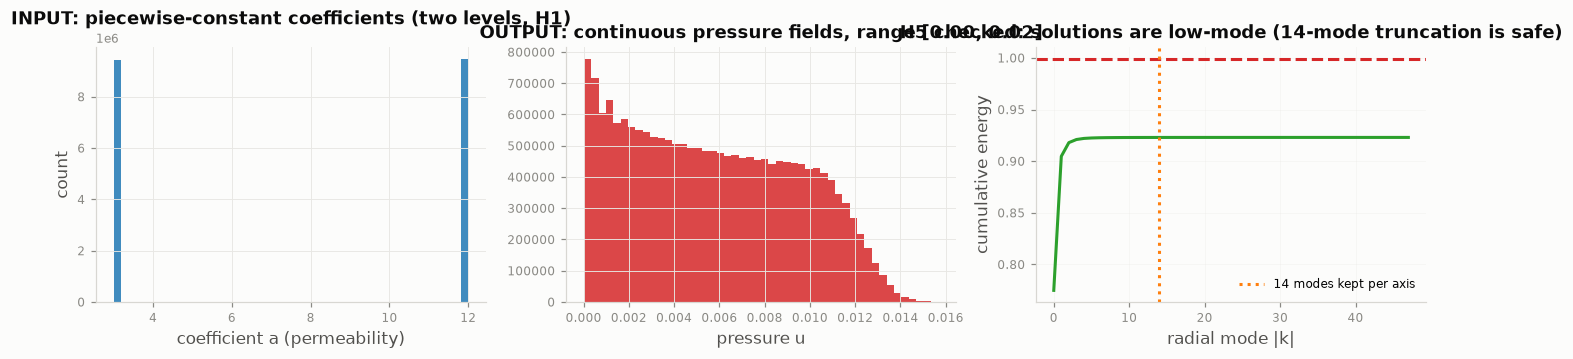

In [3]:
# ---- the pre-generated 96x96 database (shipped in data/, 85 MB, half precision) ----
DATA_FILE = project_root / 'data' / 'darcy96_big.pt'
if not DATA_FILE.exists():
    raise SystemExit('data/darcy96_big.pt is missing: regenerate it with scipy '
                     '(see the repository README), or re-clone with data/ included.')
blob = torch.load(DATA_FILE)
Atr = blob['a_tr'].float(); Utr = blob['u_tr'].float()
Ate = blob['a_te'].float(); Ute = blob['u_te'].float()
N_RES = blob['meta']['n']
print(f"loaded {Atr.shape[0]} training + {Ate.shape[0]} test pairs at {N_RES}x{N_RES} "
      f"(stored float16, {DATA_FILE.stat().st_size / 1e6:.0f} MB)")

# ---- know your data: input and output distributions + the spectral check (H5) ----
fig, ax = plt.subplots(1, 3, figsize=(12.8, 3.4))
ax[0].hist(Atr.numpy().ravel(), bins=48, color='C0', alpha=0.85)
ax[0].set_xlabel('coefficient a (permeability)'); ax[0].set_ylabel('count')
ax[0].set_title('INPUT: piecewise-constant coefficients (two levels, H1)')
ax[1].hist(Utr.numpy().ravel(), bins=48, color='C3', alpha=0.85)
ax[1].set_xlabel('pressure u')
ax[1].set_title(f'OUTPUT: continuous pressure fields, range [{float(Utr.min()):.2f}, {float(Utr.max()):.2f}]')
spec = torch.fft.rfftn(Utr.double(), dim=(-2, -1), norm='ortho').abs().pow(2).mean((0, 1))
half = spec.shape[-1]
spec1d = torch.zeros(N_RES)
for kx in range(N_RES):
    for ky in range(half):
        kk = min(int(round((kx ** 2 + ky ** 2) ** 0.5)), N_RES - 1)
        spec1d[kk] += spec[kx, ky]
cum = torch.cumsum(spec1d / spec1d.sum(), 0)
ax[2].plot(cum[:48].numpy(), color='C2')
ax[2].axhline(0.999, color='C3', ls='--')
ax[2].axvline(14, color='C1', ls=':', label='14 modes kept per axis')
ax[2].set_xlabel('radial mode |k|'); ax[2].set_ylabel('cumulative energy')
ax[2].grid(alpha=0.3); ax[2].legend(fontsize=8)
ax[2].set_title('H5 checked: solutions are low-mode (14-mode truncation is safe)')
plt.tight_layout(); plt.show()

In [4]:
# ---- the model: a SMALL factorized FNO2d, to be trained LONG ----
torch.manual_seed(0)
darcy_fno = FFNO2d(1, 1, width=20, modes=(14, 14), n_layers=5).to(DEVICE)
n_par = sum(p.numel() * (2 if p.is_complex() else 1) for p in darcy_fno.parameters())
full_par = 2 * 20 ** 2 * 14 * 14 * 5           # a full 2-D FNO with the same grid
print(f'FFNO2d(width=20, modes=(14,14), layers=5): {n_par:,} real parameters '
      f'({n_par / 140_000:.1f}x the 1-D Burgers lab model - deliberately SMALL)')
print(f'the equivalent FULL 2-D FNO would carry ~{full_par / 1e6:.2f}M spectral parameters '
      f'alone - the factorization saves ~{full_par / n_par:.0f}x here')
a_norm, u_norm = ChannelNormalizer(Atr), ChannelNormalizer(Utr)
Atr_n, Utr_n = a_norm.encode(Atr).to(DEVICE), u_norm.encode(Utr).to(DEVICE)
Ate_n, Ute_n = a_norm.encode(Ate).to(DEVICE), u_norm.encode(Ute).to(DEVICE)

FFNO2d(width=20, modes=(14,14), layers=5): 123,397 real parameters (0.9x the 1-D Burgers lab model - deliberately SMALL)
the equivalent FULL 2-D FNO would carry ~0.78M spectral parameters alone - the factorization saves ~6x here


In [5]:
# ---- training: ~5 minutes on the school GPU (MIG 1g.20gb); hours on CPU ----
EPOCHS = int(os.environ.get('DARCY_EPOCHS', '200'))
BATCH = 32
loss_fn = get_loss('rel_l2')
decay, no_decay = [], []
for p in darcy_fno.parameters():
    (no_decay if (p.is_complex() or p.ndim <= 1) else decay).append(p)
opt = torch.optim.AdamW([{'params': decay, 'weight_decay': 1e-5},
                         {'params': no_decay, 'weight_decay': 0.0}], lr=1e-3)
sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=EPOCHS * (2048 // BATCH))
gen = torch.Generator().manual_seed(0)
hist_d, snaps_d = {'train': [], 'test': []}, []
sn = Ate_n[:4]
t0 = time.time()
for ep in range(1, EPOCHS + 1):
    darcy_fno.train()
    perm = torch.randperm(2048, generator=gen)
    tot, nb = 0.0, 0
    for i in range(0, 2048, BATCH):
        idx = perm[i:i + BATCH]
        opt.zero_grad(set_to_none=True)
        loss = loss_fn(darcy_fno(Atr_n[idx]), Utr_n[idx])
        loss.backward(); opt.step(); sched.step()
        tot += loss.item(); nb += 1
    darcy_fno.eval()
    with torch.no_grad():
        pred = u_norm.decode(darcy_fno(Ate_n)).cpu()
        hist_d['train'].append(tot / nb)
        hist_d['test'].append(get_loss('rel_l2')(pred, Ute).item())
        if ep == 1 or ep % 20 == 0 or ep == EPOCHS:
            snaps_d.append((ep, u_norm.decode(darcy_fno(sn)).cpu().numpy()))
    if ep % 20 == 0 or ep == 1 or ep == EPOCHS:
        print(f'epoch {ep:3d}/{EPOCHS} | train {hist_d["train"][-1]:.4f} | '
              f'test rel-L2 {hist_d["test"][-1]:.4f} | {time.time() - t0:.0f} s', flush=True)
print(f'training done in {(time.time() - t0) / 60:.1f} min on {DEVICE}', flush=True)

epoch   1/200 | train 0.5299 | test rel-L2 0.1072 | 3 s


epoch  20/200 | train 0.0428 | test rel-L2 0.0380 | 55 s


epoch  40/200 | train 0.0277 | test rel-L2 0.0167 | 109 s


epoch  60/200 | train 0.0255 | test rel-L2 0.0157 | 163 s


epoch  80/200 | train 0.0204 | test rel-L2 0.0120 | 217 s


...

epoch 140/200 | train 0.0156 | test rel-L2 0.0095 | 379 s


epoch 160/200 | train 0.0144 | test rel-L2 0.0088 | 433 s


epoch 180/200 | train 0.0139 | test rel-L2 0.0084 | 487 s


epoch 200/200 | train 0.0138 | test rel-L2 0.0084 | 541 s


training done in 9.0 min on cuda


findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


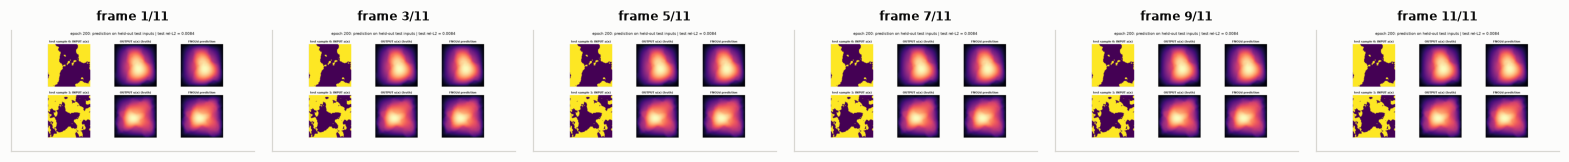

In [6]:
# ---- animation: the operator being learned at scale, epoch by epoch ----
fig, ax = plt.subplots(2, 3, figsize=(12, 6))
for j in range(2):
    ax[j, 0].imshow(Ate[j, 0].numpy(), cmap='viridis', origin='lower')
    ax[j, 0].set_title(f'test sample {j}: INPUT a(x)', fontsize=10)
    ax[j, 1].imshow(Ute[j, 0].numpy(), cmap='magma', origin='lower')
    ax[j, 1].set_title('OUTPUT u(x) (truth)', fontsize=10)
    ax[j, 2].imshow(snaps_d[0][1][j, 0], cmap='magma', origin='lower',
                    vmin=float(Ute[j].min()), vmax=float(Ute[j].max()))
    ax[j, 2].set_title('FNO2d prediction', fontsize=10)
    for k in range(3):
        ax[j, k].set_xticks([]); ax[j, k].set_yticks([])
title = fig.suptitle('')
def update(f):
    ep, pr = snaps_d[f]
    for j in range(2):
        ax[j, 2].images[0].set_data(pr[j, 0])
    title.set_text(f'epoch {ep}: prediction on held-out test inputs | '
                   f'test rel-L2 = {hist_d["test"][ep - 1]:.4f}')
show_anim(fig, update, frames=len(snaps_d), interval=700)

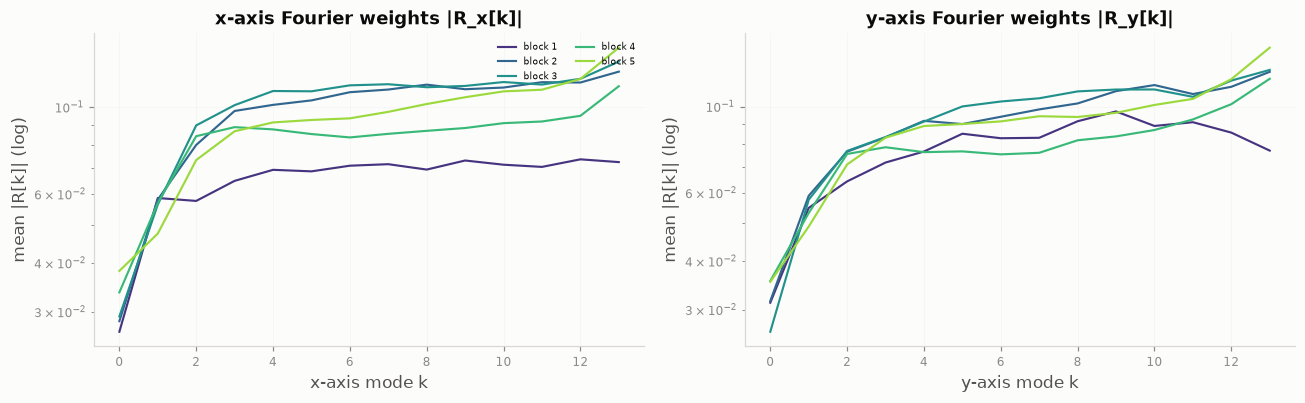

mean response: x-axis 8.87e-02 | y-axis 8.67e-02 -> ratio 1.02 (the Darcy law is isotropic: the two axes should match, and they do)
early blocks pass broadly; deeper blocks concentrate on the low modes that carry the
solution energy (H5): the spectral weights ARE the operator, in Fourier space.


In [7]:
# ---- what the blocks learned in Fourier space: the spectral weights, layer by layer ----
def spectral_responses(model):
    """Mean |R| per Fourier mode, per block and per axis: the learned transfer functions."""
    out = []
    for li, blk in enumerate(model.blocks, 1):
        wx = blk.spectral.weight_x.detach().abs().mean(dim=(0, 1)).cpu().numpy()
        wy = blk.spectral.weight_y.detach().abs().mean(dim=(0, 1)).cpu().numpy()
        out.append((li, wx, wy))
    return out

resp = spectral_responses(darcy_fno)
fig, ax = plt.subplots(1, 2, figsize=(12.0, 3.8))
cmap = plt.get_cmap('viridis')
L = len(resp)
for li, wx, wy in resp:
    c = cmap(0.15 + 0.7 * (li - 1) / max(L - 1, 1))
    ax[0].plot(np.arange(len(wx)), np.maximum(wx, 1e-9), '-', color=c, lw=1.4, label=f'block {li}')
    ax[1].plot(np.arange(len(wy)), np.maximum(wy, 1e-9), '-', color=c, lw=1.4)
for a, (ttl, axis) in zip(ax, [('x-axis Fourier weights |R_x[k]|', 'x'), ('y-axis Fourier weights |R_y[k]|', 'y')]):
    a.set_yscale('log'); a.set_xlabel(f'{axis}-axis mode k')
    a.set_ylabel('mean |R[k]| (log)'); a.grid(alpha=0.3); a.set_title(ttl)
ax[0].legend(fontsize=6, ncol=2, loc='upper right')
plt.tight_layout(); plt.show()
rx = np.mean([wx.mean() for _, wx, _ in resp]); ry = np.mean([wy.mean() for _, _, wy in resp])
print(f'mean response: x-axis {rx:.2e} | y-axis {ry:.2e} -> ratio {rx / ry:.2f} '
      '(the Darcy law is isotropic: the two axes should match, and they do)')
print('early blocks pass broadly; deeper blocks concentrate on the low modes that carry the')
print('solution energy (H5): the spectral weights ARE the operator, in Fourier space.')

test metrics: {'l1': 0.0, 'l2': 0.0, 'rel_l1': 0.0076, 'rel_l2': 0.0084}
test rel-L2: mean 0.0084 | median 0.0080 | worst 0.0178


findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


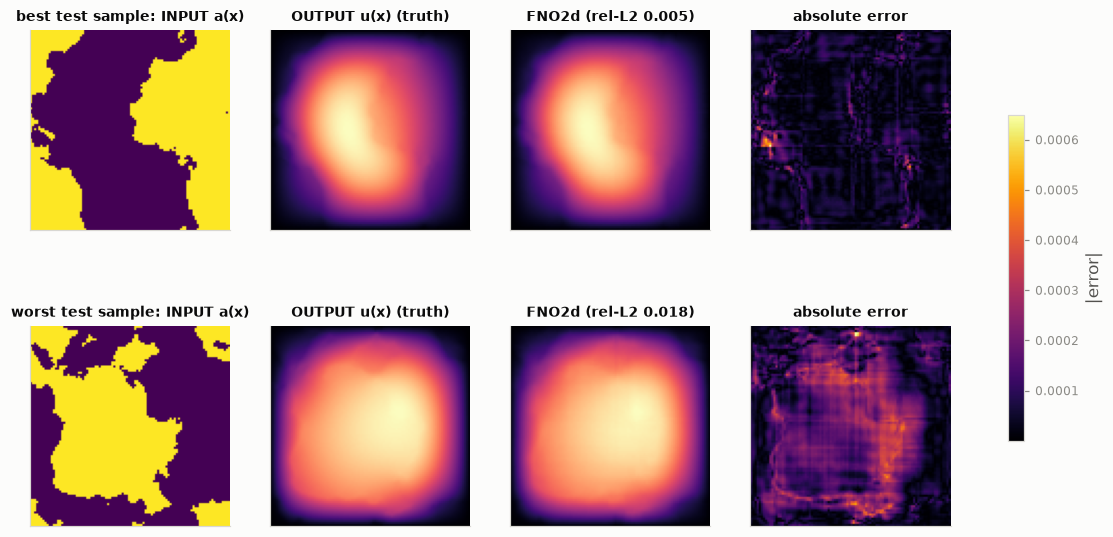

In [8]:
# ---- final evaluation: physical units, worst cases, the four metrics (H4) ----
darcy_fno.eval()
with torch.no_grad():
    pred = u_norm.decode(darcy_fno(Ate_n)).cpu()
print('test metrics:', {k: round(v, 4) for k, v in all_metrics(pred, Ute).items()})
rel = (pred.flatten(1) - Ute.flatten(1)).norm(dim=1) / Ute.flatten(1).norm(dim=1)
i_best, i_worst = int(rel.argmin()), int(rel.argmax())
print(f'test rel-L2: mean {rel.mean():.4f} | median {rel.median():.4f} | '
      f'worst {rel.max():.4f}')

fig, ax = plt.subplots(2, 4, figsize=(13.5, 6.4))
for row, (i, lbl) in enumerate([(i_best, 'best test sample'), (i_worst, 'worst test sample')]):
    ax[row, 0].imshow(Ate[i, 0].numpy(), cmap='viridis', origin='lower')
    ax[row, 0].set_title(f'{lbl}: INPUT a(x)', fontsize=9)
    ax[row, 1].imshow(Ute[i, 0].numpy(), cmap='magma', origin='lower')
    ax[row, 1].set_title('OUTPUT u(x) (truth)', fontsize=9)
    ax[row, 2].imshow(pred[i, 0].numpy(), cmap='magma', origin='lower')
    ax[row, 2].set_title(f'FNO2d (rel-L2 {rel[i]:.3f})', fontsize=9)
    im = ax[row, 3].imshow((pred[i, 0] - Ute[i, 0]).abs().numpy(), cmap='inferno', origin='lower')
    ax[row, 3].set_title('absolute error', fontsize=9)
    for a in ax[row]: a.set_xticks([]); a.set_yticks([])
fig.colorbar(im, ax=ax, shrink=0.6, label='|error|')
plt.show()

**Reading the scale-up — and its limits.**

- **Same skeleton, bigger numbers.** Nothing changed methodologically: hypotheses stated and
  checked (H5's spectral test), training statistics only, relative $L^2$ in physical units,
  worst cases inspected. What changed is *scale*: 2304 pairs at 96×96 and a schedule two orders of magnitude
  longer than the labs', ~5 GPU minutes — trained from scratch, end to end, in one notebook
  cell, with its learned Fourier weights dissected layer by layer.
- **The budget.** Two hundred epochs (a full cosine schedule over ~13,000 updates) is the
  *long-schedule* regime: a small network seeing each 96×96 sample a hundred times, annealed
  slowly. Measured on the school's `MIG 1g.20gb` slice this takes ~10 minutes (a full H100
  would do it in a fraction of that; on a laptop CPU set `DARCY_EPOCHS` to 10-20). The
  operator-learning literature combines long schedules WITH more width to reach ~0.01 test
  rel-$L^2$; our number is what the small factorized model reaches in this regime, and the
  executed solution contains the exact run.
- **Transfer.** Swapping the data cell for your own gridded input/output pairs is the only
  change needed to use this notebook as a template for your own 2-D operator problems.

### Optional — save this interactive session measurement (Hedy only)

## References

**Operator learning and FNO/FFNO:**
- Z. Li, N. Kovachki, K. Azizzadenesheli, B. Liu, K. Bhattacharya, A. Stuart, A. Anandkumar.
  *Fourier Neural Operator for Parametric Partial Differential Equations.* ICLR 2021.
- Z. Li, N. Kovachki, ... A. Anandkumar. *Neural Operator: Learning Maps Between Function
  Spaces.* Nature Machine Intelligence **6**, 666–676 (2024).
- A. Tran, A. Mathews, L. Xie, C.-K. Ong. *Factorized Fourier Neural Operators.* ICLR 2023.
- K. Azizzadenesheli, Z. Li, ... A. Anandkumar. *Neural Operators for Accelerating Scientific
  Simulations? Open Problems and Perspectives.* ICLR 2024 (position paper).

**Graph neural networks:**
- T. N. Kipf, M. Welling. *Semi-Supervised Classification with Graph Convolutional Networks.*
  ICLR 2017.
- J. Gilmer, S. S. Schoenholz, P. F. Riley, O. Vinyals, G. E. Dahl. *Neural Message Passing for
  Quantum Chemistry.* NeurIPS 2017.
- Q. Li, Z. Han, X.-M. Wu. *Deeper Insights into Graph Convolutional Networks for Semi-
  Supervised Learning.* AAAI 2018. (Oversmoothing and the Dirichlet-energy analysis.)
- R. L. Murphy, B. Srinivasan, V. Rao, B. Ribeiro. *Janossy Pooling: Learning Deep
  Permutation-Invariant Functions.* NeurIPS 2019. (Why permutation-invariant aggregation
  matters.)

**Loss landscapes and optimization:**
- H. Li, Z. Xu, G. Taylor, C. Studer, T. Goldstein. *Visualizing the Loss Landscape of Neural
  Nets.* NeurIPS 2018. (The 2-D random-slice methodology used in Lab 1 §4.)
- T. Garipov, P. Izmailov, D. Podoprikhin, D. Vetrov, A. Wilson. *Loss Surfaces, Mode
  Connectivity, and Fast Ensembling of DNNs.* NeurIPS 2018. (Why two trained networks are
  connected by a low-loss path — the multi-minimum geometry of Lab 1 §4.4.)

**Infrasound propagation and parabolic-equation methods:**
- A. Le Pichon, E. Blanc, A. Hauchecorne (eds.). *Infrasound Monitoring for Atmospheric
  Studies.* 2nd ed., Springer (2021).
- R. Waxler, J. Assink. *Propagation of infrasound through the atmosphere: theory and
  observations.* In: Infrasound Monitoring, ch. 5 (2019).
- D. P. Knupp, S. J. Franke. *A global reference atmosphere for infrasound propagation.*
  J. Acoust. Soc. Am. **140**, 2724 (2016).

**Software:**
- A. Paszke et al. *PyTorch: An Imperative Style, High-Performance Deep Learning Library.*
  NeurIPS 2019.
- M. Fey, J. E. Lenssen. *Fast Graph Representation Learning with PyTorch Geometric.*
  ICLR Workshop on Representation Learning on Graphs and Manifolds (2019).


In [9]:
if HEDY_SESSION is not None:
    HEDY_SESSION.report()   # writes a JSON timing report on the Hedy cluster only
else:
    print('No Hedy session: nothing to report (laptop run).')

Interactive measurement saved: /home/projects/m26266/letma2026-ml-labs/notebooks/extensions/reports/interactive/scaleup_darcy_fno2d_25685_20261029T114347Z.json
Session elapsed (including user idle): 544.898 s
Peak kernel RSS: 2134.31 MiB
PyTorch CUDA peak allocated/reserved: 2647.94 / 6220.0 MiB
